# Amazon 2023: saved DUPGT training results

## 1. Load the completed run

In [1]:
from pathlib import Path
import gc, json, sys
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
ROOT=next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/dupgt_cdr').is_dir())
sys.path.insert(0,str(ROOT/'src'))
YEAR='2023'
RUN=ROOT/f'outputs/amazon{YEAR}/full_seed2020'
RUNS={YEAR:RUN}
CONFIG=json.loads((RUN/'config.json').read_text())
DATASET=json.loads((RUN/'dataset_manifest.json').read_text())
METRICS=json.loads((RUN/'metrics.json').read_text())
assert METRICS['status']=='completed'
print('Run:',RUN)
print('Device:',METRICS['environment']['device'],'| Seed:',METRICS['seed'])

Run: /Users/parjanyapandey/Programming/Masters/Data Mining/dupgt-cdr/outputs/amazon2023/full_seed2020
Device: cpu | Seed: 2020


## 2. Dataset and held-out users

A **shared user** has Book and Movie ratings in the raw data.

The cell below reads counts from the saved manifest, so it is quick even though the raw files are large.

In [2]:
m=DATASET
summary=pd.DataFrame([
 ['Book ratings read',m['raw']['source_ratings']],
 ['Movie ratings read',m['raw']['target_ratings']],
 ['Users in both domains',m['cohort']['shared_users']],
 ['Held-out Movie test users',m['splits']['test']['users']],
 ['Held-out Movie ratings',m['splits']['test']['ratings']],
],columns=['Quantity','Count'])
display(summary.style.format({'Count':'{:,.0f}'}))
splits=pd.DataFrame([[name.replace('_',' ').title(),v['users'],v['ratings']]
 for name,v in m['splits'].items()],columns=['Saved split','Users','Ratings'])
display(splits.style.format({'Users':'{:,.0f}','Ratings':'{:,.0f}'}))
print('Unseen Movie items excluded from test:',m['evaluation_filter']['test_cold_item_rows_excluded'])

,Quantity,Count
0,Book ratings read,"9,488,297"
1,Movie ratings read,"7,441,129"
2,Users in both domains,"127,188"
3,Held-out Movie test users,"25,438"
4,Held-out Movie ratings,"433,618"


,Saved split,Users,Ratings
0,Source Train,"776,370","9,488,297"
1,Target Train,"619,046","6,797,056"
2,Meta Train,"89,031","1,497,886"
3,Validation,"12,719","210,455"
4,Test,"25,438","433,618"


Unseen Movie items excluded from test: 0


## 3. Training stages and settings

First the code learns Book and Movie factors from ratings. Then a **linear mapping** learns a simple Book-to-Movie bridge. Finally, **DUPGT** builds separate paths for high Book ratings (4–5) and low ratings (1–3) and learns how to mix them for a candidate Movie.

This cell *displays* the settings that were used. The training loops are in [`train.py`](../src/dupgt_cdr/train.py), and the DUPGT network is in [`upstream.py`](../src/dupgt_cdr/upstream.py) and [`model.py`](../src/dupgt_cdr/model.py).

In [3]:
settings=pd.DataFrame([
 ['Book factors',CONFIG['pretrain_epochs'],CONFIG['pretrain_learning_rate'],'Book-side vectors'],
 ['Movie factors',CONFIG['pretrain_epochs'],CONFIG['pretrain_learning_rate'],'Movie-side vectors'],
 ['Linear mapping',CONFIG['mapping_epochs'],CONFIG['mapping_learning_rate'],'Simple Book-to-Movie transfer'],
 ['DUPGT',CONFIG['meta_epochs'],CONFIG['meta_learning_rate'],'High/low history with a learned gate'],
],columns=['Stage','Epochs','Learning rate','What is learned'])
display(settings)
print('Embedding dimension:',CONFIG['embedding_dim'])
print('Factor batch size:',CONFIG['batch_size'],'| DUPGT batch size:',CONFIG['meta_batch_size'])

,Stage,Epochs,Learning rate,What is learned
0,Book factors,15,0.02,Book-side vectors
1,Movie factors,15,0.02,Movie-side vectors
2,Linear mapping,30,0.01,Simple Book-to-Movie transfer
3,DUPGT,15,0.02,High/low history with a learned gate


Embedding dimension: 10
Factor batch size: 1024 | DUPGT batch size: 256


## 4. Training curves saved by the run

`training_history.csv` has one row per epoch. **Training MSE** is average squared error while fitting ratings. **Validation RMSE** is error on a separate group used to select transfer weights. Lower is better, but MSE and RMSE are different measures. The cell summarizes the last logged epoch of each stage and shows the original `training_curves.png` used in the PDF.

,stage,epoch,train_mse,validation_rmse
14,source_pretrain,15,0.1969,—
29,target_pretrain,15,0.2377,—
59,linear_mapping,30,0.5637,1.0918
74,dupgt,15,0.9303,0.9960


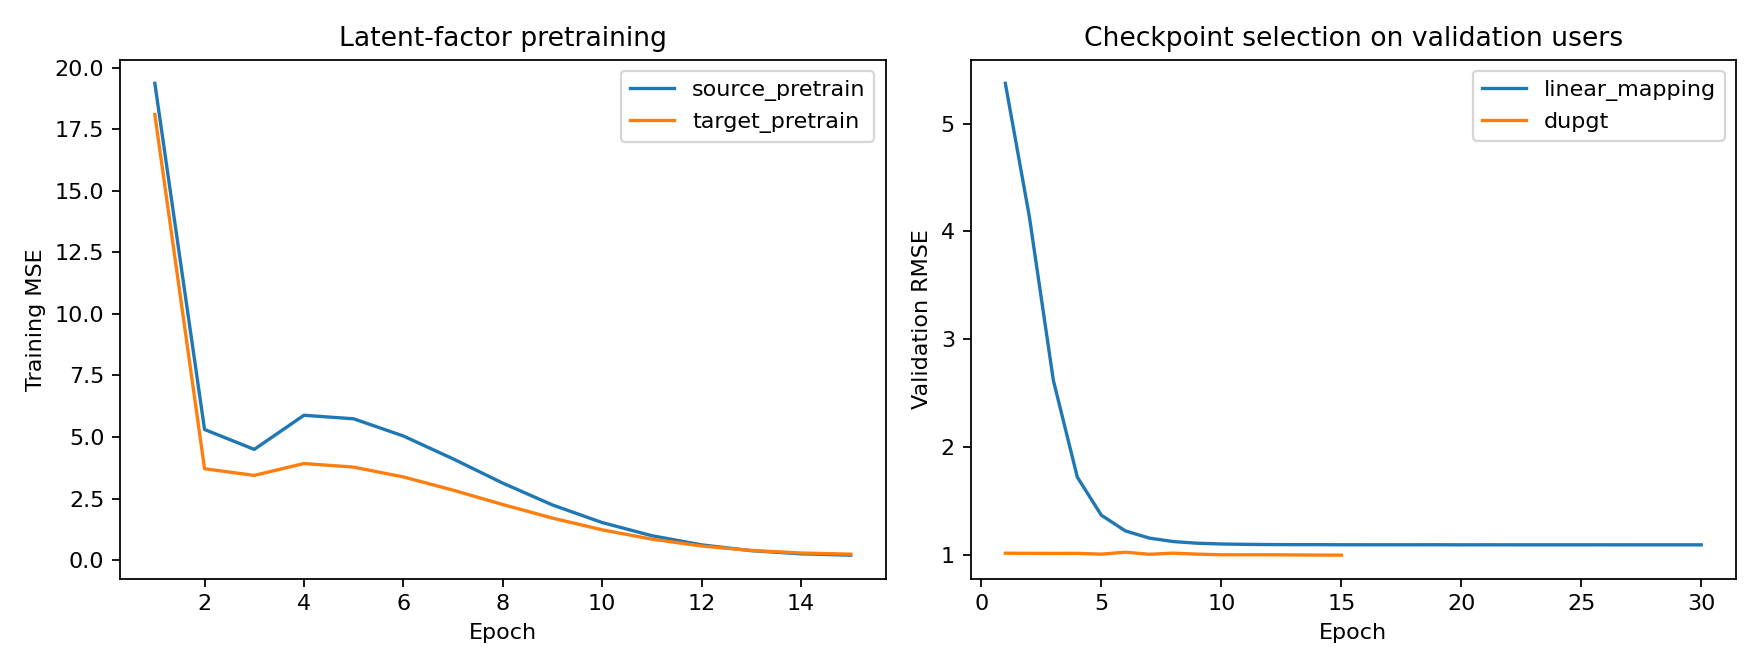

In [4]:
history=pd.read_csv(RUN/'training_history.csv')
last=history.groupby('stage',sort=False).tail(1)[['stage','epoch','train_mse','validation_rmse']]
display(last.style.format({'train_mse':'{:.4f}','validation_rmse':'{:.4f}'},na_rep='—'))
display(Image(filename=str(RUN/'training_curves.png')))

## 5. Saved checkpoints

A **checkpoint** is a file of learned weights. Factor weights were saved after pretraining. The linear-mapping and DUPGT checkpoints were selected using the lowest *validation* RMSE, before checking the test scores. This cell shows the selected epochs; it does not choose new weights.

In [5]:
chosen=METRICS['selected_checkpoints']
checkpoints=pd.DataFrame([
 ['Linear mapping','linear_mapping_best.pt',chosen['linear_mapping']['epoch'],chosen['linear_mapping']['validation']['rmse']],
 ['DUPGT','dupgt_best.pt',chosen['dupgt']['epoch'],chosen['dupgt']['validation']['rmse']],
],columns=['Model','Weight file','Selected epoch','Validation RMSE'])
display(checkpoints.style.format({'Validation RMSE':'{:.4f}'}))
print('Factor weights: pretrained_factors.pt')

,Model,Weight file,Selected epoch,Validation RMSE
0,Linear mapping,linear_mapping_best.pt,27,1.0917
1,DUPGT,dupgt_best.pt,15,0.9960


Factor weights: pretrained_factors.pt


## 6. Held-out test scores

**MAE** is average absolute error in stars. **RMSE** penalizes large errors more. Both should be lower. Global mean predicts one training average; Movie mean predicts each Movie's training average; linear mapping transfers a Book-user vector; DUPGT uses the high/low Book paths. The code reads the *raw* test metrics saved for the whole test set and displays the original `test_metrics.png` from the PDF.

,Model,Test MAE,Test RMSE
0,Global mean,0.9110,1.1432
1,Movie mean,0.7620,1.0507
2,Linear mapping,0.8336,1.1055
3,DUPGT,0.7230,1.0119


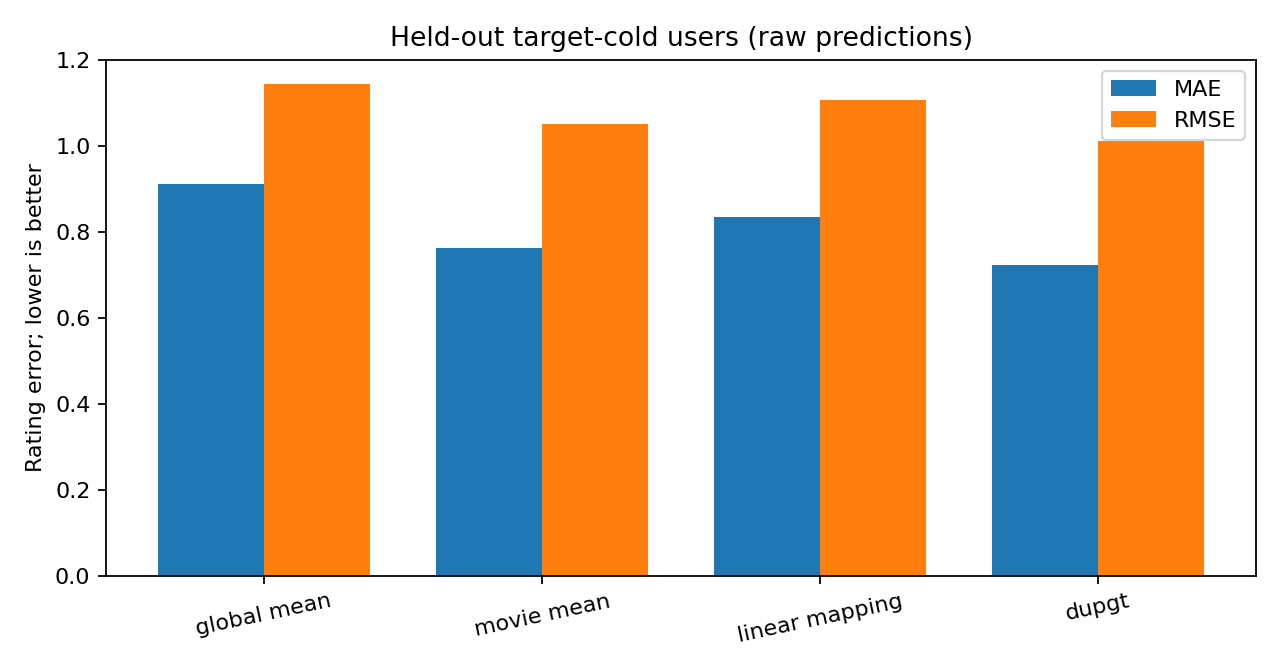

In [6]:
labels=[('global_mean','Global mean'),('movie_mean','Movie mean'),
        ('linear_mapping','Linear mapping'),('dupgt','DUPGT')]
results=pd.DataFrame([[name,METRICS['results'][key]['raw']['mae'],METRICS['results'][key]['raw']['rmse']]
 for key,name in labels],columns=['Model','Test MAE','Test RMSE'])
display(results.style.format({'Test MAE':'{:.4f}','Test RMSE':'{:.4f}'}))
display(Image(filename=str(RUN/'test_metrics.png')))

The next calculation compares DUPGT with **Movie mean on the same test rows**. Positive reductions mean DUPGT made smaller errors. This comparison is stronger evidence of useful Book-to-Movie transfer than comparing 2014 directly with 2023, because the releases contain different users and items.

In [7]:
base=METRICS['results']['movie_mean']['raw']
dupgt=METRICS['results']['dupgt']['raw']
print(f"MAE reduction: {base['mae']-dupgt['mae']:.4f} stars ({100*(base['mae']-dupgt['mae'])/base['mae']:.2f}%)")
print(f"RMSE reduction: {base['rmse']-dupgt['rmse']:.4f} stars ({100*(base['rmse']-dupgt['rmse'])/base['rmse']:.2f}%)")
print(f"Held-out Movie ratings evaluated: {dupgt['n_ratings']:,}")

MAE reduction: 0.0390 stars (5.11%)
RMSE reduction: 0.0388 stars (3.69%)
Held-out Movie ratings evaluated: 433,618


## 7. Gate and individual-user results

DUPGT combines a high-rated Book path and a low-rated Book path for each Movie. The **high gate** is its mixing weight, *not* a confidence probability. A lower overall error also does not mean every person benefited. This cell reads the saved user-level CSV and counts who had lower or higher MAE than Movie mean.

In [8]:
gate=METRICS['gate_summary']
print(f"Mean high-Book gate weight: {gate['mean_high_weight']:.3f}")
users=pd.read_csv(RUN/'user_metrics.csv')
diff=users['dupgt_minus_movie_mean_mae']
user_table=pd.DataFrame([
 ['DUPGT better',int((diff<0).sum()),100*(diff<0).mean()],
 ['Equal',int((diff==0).sum()),100*(diff==0).mean()],
 ['Movie mean better',int((diff>0).sum()),100*(diff>0).mean()],
],columns=['Per-user MAE comparison','Users','Share'])
display(user_table.style.format({'Users':'{:,.0f}','Share':'{:.1f}%'}))

Mean high-Book gate weight: 0.884


,Per-user MAE comparison,Users,Share
0,DUPGT better,"14,763",58.0%
1,Equal,0,0.0%
2,Movie mean better,"10,675",42.0%


## 8. A few saved prediction rows

This reads `example_predictions.csv`, a small excerpt of the complete test export. `actual_rating` is the withheld answer. `dupgt` is the raw model prediction, which can fall outside 1–5 before display clipping. The two gate weights add to one; the Book counts show how many high and low ratings the user had. The rating datasets contain product IDs, not Movie titles.

In [9]:
sample=pd.read_csv(RUN/'example_predictions.csv',nrows=8,dtype={'user_id':str,'movie_asin':str})
columns=['user_id','movie_asin','actual_rating','movie_mean','dupgt','alpha_high','alpha_low','source_high_count','source_low_count']
display(sample[columns].style.format({'movie_mean':'{:.3f}','dupgt':'{:.3f}',
                                      'alpha_high':'{:.3f}','alpha_low':'{:.3f}'}))

,user_id,movie_asin,actual_rating,movie_mean,dupgt,alpha_high,alpha_low,source_high_count,source_low_count
0,AH36N5HJJQCBDAURJUTFAIB4GRFA,B00005RDRD,4,3.250,4.240,0.907,0.093,449,12
1,AHOJXB5GINIITSUDEX3N2ONQJUUQ,B004EPYZPS,4,4.230,3.723,0.926,0.074,27,2
2,AEORXT6YA2MPEOJKC75MZKSHODFA,B008FTX6OU,5,4.705,4.278,0.903,0.097,23,3
3,AH7GBM4FIIUSGWCRSOYMYIVSF43A,B003ZUTTDG,5,4.143,4.912,0.907,0.093,43,0
4,AFWAJ4VKN6FMF6VWNKXCSQ7QQQYQ,B00WU5B494,5,4.460,4.553,0.875,0.125,12,0
5,AETFKQ53VJ4MVM7ZVFHFTFXGP25A,B00E9EJ02C,5,4.900,4.784,0.917,0.083,19,1
6,AGFYTGMPSPR37LVQEG5ALGYCHLNQ,B008Y6O8ZA,4,3.898,3.741,0.903,0.097,2,4
7,AGK2GVFQQWDEIAJ4IOYML5EOKU4Q,B00E8AVN9U,5,4.829,4.949,0.952,0.048,6,0


## 10. Run the saved DUPGT weights once

This final demonstration reloads `dupgt_best.pt` and makes eight fresh predictions using real held-out user–Movie pairs and their Book histories. It checks that these match the original exported values. Loading the large arrays and checkpoint takes longer than the tables, but it **does not retrain**.

In [11]:
from dupgt_cdr.data import get_benchmark
from dupgt_cdr.model import DUPGTModel
from dupgt_cdr.settings import get_config

def run_saved_dupgt(year, n=8):
    config = get_config(year, "full")
    data, manifest = get_benchmark(config)
    run = RUNS[year]
    checkpoint = torch.load(run / "checkpoints/dupgt_best.pt", map_location="cpu", weights_only=True)
    assert checkpoint["dataset_sha256"] == manifest["benchmark_sha256"], "Checkpoint/data mismatch"
    torch.set_num_threads(4)
    model = DUPGTModel(**checkpoint["model_spec"])
    model.load_state_dict(checkpoint["model_state"])
    model.eval()

    rows = data["test"][:n]
    features = np.concatenate((rows[:, :2], data["histories"][rows[:, 0]]), axis=1)
    with torch.inference_mode():
        predicted, high_gate = model.forward_with_gate(torch.as_tensor(features, dtype=torch.long))
    predicted = predicted.numpy().reshape(-1)
    high_gate = high_gate.numpy().reshape(-1)
    exported = pd.read_csv(run / "test_predictions.csv.gz", nrows=n,
                           dtype={"user_id": str, "movie_asin": str})
    max_difference = float(np.max(np.abs(predicted - exported["dupgt"].to_numpy())))
    assert np.allclose(predicted, exported["dupgt"], atol=1e-5, rtol=1e-5)

    counts = data["polarity_counts"][rows[:, 0]]
    example = pd.DataFrame({"User ID": exported["user_id"], "Movie ID": exported["movie_asin"],
                            "Actual stars": rows[:, 2], "DUPGT prediction": predicted,
                            "Movie mean": exported["movie_mean"], "High gate": high_gate,
                            "High Books": counts[:, 0], "Low Books": counts[:, 1]})
    display(example.style.format({"DUPGT prediction": "{:.3f}", "Movie mean": "{:.3f}",
                                  "High gate": "{:.3f}"}))
    print(f"Amazon {year}: {n} live predictions match the saved export; maximum difference = {max_difference:.2g}")
    del data, checkpoint, model
    gc.collect()
    return example

In [12]:
live_example=run_saved_dupgt(YEAR, n=8)

,User ID,Movie ID,Actual stars,DUPGT prediction,Movie mean,High gate,High Books,Low Books
0,AHZ6XMOLEWA67S3TX7IWEXXGWSOA,B007N320G4,5,4.662,4.771,0.908,9,2
1,AHZ6XMOLEWA67S3TX7IWEXXGWSOA,B00AMSS3TU,5,4.703,4.860,0.905,9,2
2,AHZ6XMOLEWA67S3TX7IWEXXGWSOA,B005ERX1Z0,5,4.269,4.556,0.890,9,2
3,AHZ6XMOLEWA67S3TX7IWEXXGWSOA,B004R6JG7G,5,4.466,4.614,0.895,9,2
4,AHZ6XMOLEWA67S3TX7IWEXXGWSOA,B00AEFXQS4,5,4.012,4.500,0.904,9,2
5,AHZ6XMOLEWA67S3TX7IWEXXGWSOA,B00HVBB140,5,4.785,4.840,0.898,9,2
6,AFAIJYOUO3NAWLBDIKTQSC3DASWA,B000063UR1,5,4.017,4.413,0.899,9,3
7,AFAIJYOUO3NAWLBDIKTQSC3DASWA,B00026L8O4,5,4.064,4.364,0.888,9,3


Amazon 2023: 8 live predictions match the saved export; maximum difference = 9.5e-07
